# Week 8: Logistic Regression Classification(, Support Vector Machines)

# First time here?



1.   Copy this file to your Google Drive so you can edit it: **File->Save a copy in Drive** (requires a personal Google account)
2.   Done? Consider giving your copy a better name (e.g., including your name and/or student ID) - just click on the filename in the top left and edit it.
3.   (Want to re-open your copy in future? Go: **File->Open notebook** and select the Google Drive tab)
4.   (Want to find your file on your Google Drive? Google puts Colab files in a folder called "Colab Notebooks")

# Scikit-learn implementations (LoR)

In this notebook we're going to focus on using an existing logistic regression (LoR) implementation: the one provided by the [Scikit-learn](https://scikit-learn.org/stable/) package.

As well as learning how to use it, we'll introduce/revisit some different methods for evaluating and interpreting the models it produces.

In the extension exercises, there is a chance to work on re-implementing the model for yourself.

## From last time

This lab builds on the topics we learned about in the previous one - make sure you've completed that first.

Recall that gradient descent can be much faster for fitting a linear regressor (than solving the Normal equation) when you have a large amount of training data. In many other areas of supervised learning (and machine learning more widely) it's not just an option, it's the only option...

Recall from our work this week that we can use a linear regressor for solving classification tasks by putting the final output through a sigmoid function (specifically a logistic function) and trying to predict class probability scores (between 0 and 1). This kind of classification model is called a logistic regressor, and the _only_ way to recover its model parameters is by using gradient descent (there is no analytical solution, or complicated equation we can solve).

The cost function is different (called the 'log loss', see the Moodle materials for details if you're interested), and some implementations use alternatives to SGD for the gradient descent step, but all the important ideas are exactly the same. We're calculating local gradients in the cost surface in order to make small improvements to our model parameter estimates.

Once again, the cost surface is unimodal and so we can expect to recover the best possible model parameters if we descend carefully.

Scikit-learn's `SGDClassifier` class implements logistic regression using SGD and we evaluate it on the biopsies.csv data below.

**Tip**: You might also have come across the `LogisticRegression` class, which does essentially the same thing but using alternatives algorithms to SGD for the gradient descent.

**Tip**: We would normally start off with the iris.csv data, but we're avoiding it here because it's a multiclass problem (with >2 possible labels). More on how to solve these with LoR a little later on.

## Basic supervised learning recipe

The code below shows our basic supervised learning recipe again. This time we're using it to train and evaluate on the biopsies.csv data, and we're using [Scikit-learn](https://scikit-learn.org/stable/)'s logistic regression classifier implementation.

*   How accurate is the model? ** 94.7 % **

**Tip**: logistic regression models are sensitive to predictive feature value ranges, and so we're using z-score standardisation via the `StandardScaler` class.

In [4]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Create a logistic regression classification model object:
model = SGDClassifier(random_state=99, loss='log_loss', verbose=1, n_iter_no_change= 10)

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

-- Epoch 1
Norm: 124.82, NNZs: 30, Bias: -12.900374, T: 342, Avg. loss: 4.335751
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 116.22, NNZs: 30, Bias: -6.438631, T: 684, Avg. loss: 2.004798
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 129.01, NNZs: 30, Bias: -12.887753, T: 1026, Avg. loss: 3.275181
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 111.58, NNZs: 30, Bias: -3.014541, T: 1368, Avg. loss: 1.107021
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 97.17, NNZs: 30, Bias: -1.319880, T: 1710, Avg. loss: 1.596140
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 89.14, NNZs: 30, Bias: -2.187856, T: 2052, Avg. loss: 1.293894
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 89.52, NNZs: 30, Bias: -1.972175, T: 2394, Avg. loss: 1.431453
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 83.01, NNZs: 30, Bias: -5.611337, T: 2736, Avg. loss: 0.808044
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 78.25, NNZs: 30, Bias: -4.784504, T: 3078, Avg. loss: 0.948

## Useful hyperparameters

The same hyperparameters that were useful to us in SGD-based linear regression are also useful for SGD-based logistic regression classification (i.e., `eta0`, `tol` and `n_iter_no_change`).

## You try one

Check you can influence the number of epochs by changing a hyperparameter.

How many epochs are completed now? ** i added n_iter_no_change to 10 and the number of epochs increased from 41 to 46 *Tip**: You won't be able to bring about big improvements in terms of the performance on the testing data (SGD is already converging on the global minimum), but check you can get some control over the number of training epochs that are taking place.

# The underlying linear regressor

At the heart of a logistic regressor is a linear regressor. It maps a collection of predictive feature values into a single output (via a linear relationship). The parameters of the linear regressor are stored in the same class attributes we met last time: `.coef_` and `.intercept_`.

## 1D model parameter visualisation

Below we reuse some code from the last notebook to plot the 10 strongest coefficients.

*    Which predictive feature has the greatest effect on the output of the linear regressor? ** Texture worst **

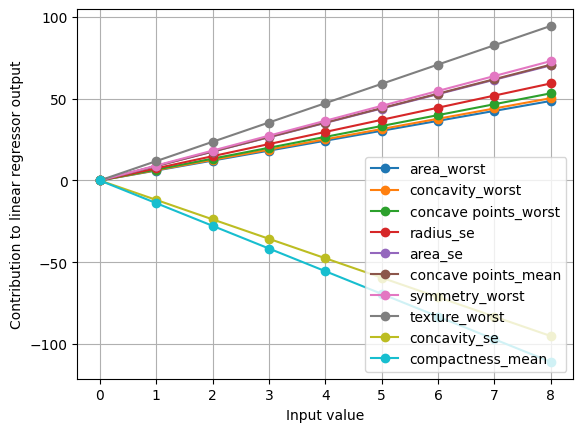

And the final constant offset is: -0.744


In [5]:
import matplotlib.pyplot as plt

# Grab a record of the predictive features
predictive_features = observations.drop(columns=target_feature).columns.to_numpy()

# get all the model parameters
coef_ = model.coef_[0]
# keep only the top 10 strongest
idx = np.argsort(np.abs(coef_))[-10:]
coef_ = coef_[idx]
predictive_features = predictive_features[idx]

# Show the strongest learned coefficients (model parameters) graphically
plt.figure()
for index, c in enumerate(coef_):
  plt.plot(range(0,9), range(0,9)*c, marker='o', linestyle='-', label=predictive_features[index])
plt.xlabel('Input value')
plt.ylabel('Contribution to linear regressor output')
plt.grid(True)
plt.legend()
plt.show()

# And the constant offset
print(f"And the final constant offset is: {model.intercept_[0]:.3f}")

# Class label probabilities

The output from the linear regressor goes through a logistic function to generate probabilities for the positive class label.

The code below defines a simple logistic function. We then grab the parameters of the underlying linear regressor and use them to generate predictions for _all_ the testing data using a single matrix multiplication. Finally, we pass the results into the logistic function to generate positive class probabilities. We also print out the results produced by the model's `.predict_proba()` method for comparison:

*    Have a careful look at the two sets of results - do they match? ** No**

In [6]:
import numpy as np

def logistic(x):
  return 1 / (1 + np.exp(-x))

# Use the underlying linear regressor to generate predictions for our testing examples manually, with a matrix multiply

# Add a column of ones to the matrix of testing examples to account for the intercept
test_examples_with_intercept = np.c_[test_examples, np.ones((test_examples.shape[0], 1))]
# Get the model's parameters (coefficients and intercept) into a matrix with a single column ('column vector')
params = np.atleast_2d(np.append(model.coef_, model.intercept_)).T
# Calculate the linear regression predictions using a single matrix multiply
predictions = test_examples_with_intercept @ params

# Compute the logistic function responses and print
predictions = logistic(predictions)
print(predictions)

# print the probabilities produced by the model
print(model.predict_proba(test_examples))

[[1.00000000e+00]
 [9.95385954e-01]
 [1.00000000e+00]
 [5.01377661e-02]
 [1.00000000e+00]
 [1.12493447e-05]
 [2.73792076e-08]
 [4.25738443e-12]
 [6.20039346e-07]
 [2.18044682e-03]
 [4.96209870e-01]
 [1.00000000e+00]
 [3.07809939e-09]
 [5.07906049e-09]
 [1.00000000e+00]
 [1.82426269e-17]
 [1.00000000e+00]
 [2.36031848e-03]
 [4.93642467e-14]
 [9.99870896e-01]
 [1.70611769e-07]
 [1.09421525e-14]
 [1.30482373e-05]
 [1.60528898e-15]
 [9.92451168e-16]
 [3.73077636e-06]
 [9.99999958e-01]
 [1.00699106e-05]
 [9.99991213e-01]
 [1.00000000e+00]
 [1.00000000e+00]
 [3.53889406e-09]
 [2.00404111e-01]
 [1.00000000e+00]
 [5.37055962e-28]
 [9.14464227e-15]
 [8.73169339e-01]
 [8.10478629e-19]
 [1.00000000e+00]
 [2.29663093e-17]
 [1.00000000e+00]
 [1.00000000e+00]
 [2.34900289e-03]
 [7.62259075e-10]
 [8.43353072e-25]
 [9.99999423e-01]
 [1.51175857e-14]
 [2.95390120e-03]
 [2.30606062e-13]
 [9.48342553e-11]
 [8.76950336e-09]
 [5.86044382e-13]
 [3.36053479e-07]
 [1.58217950e-16]
 [5.61524127e-04]
 [1.241491

# Multiclass problems

For multiclass classification problems, only Scikit-learn's `LogisticRegression` class supports use of a 'softmax' function (and cross-entropy cost function). However, both the `LogisticRegression` class and the `SGDClassifier` class support the approach of training multiple models, one per label. Each model classifies one label versus 'all-the-rest' (e.g., 'setosa' versus 'not setosa'), and an overall prediction is made based on the resulting `predict_proba()` scores. The overall approach is sometimes called 'one-versus-all'.

In practice, logistic regression classification with multiclass problems like the iris.csv data "just works", regardless of which Scikit-learn class you choose to use.

# The moons.csv data

Let's switch to the moons.csv data (which has only two predictive features) and do some visualisation. We'll look at the model parameters and the class label probabilities as well as the final generalisation.

## The underlying linear regressor

First let's see the linear regression result at the heart of the model, using the same feature space visualisation approaches we developed in the previous notebook (colour to represent the regressor's output in a 2D space; an extra dimension to represent the regressor's output in a 3D space):

*    Try to notice where the regressor produces an output of zero. What is the shape of this region in the regression space? ** There is no obvious shape**

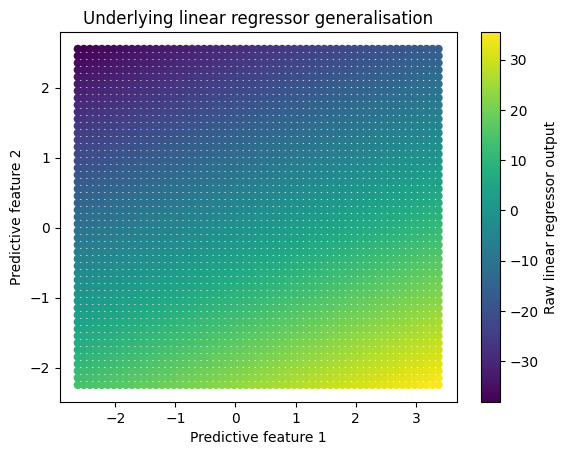

In [7]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.linear_model import SGDClassifier
import matplotlib.pyplot as plt
import plotly.graph_objects as go

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/moons.csv')

# Set the name of the target feature
target_feature = 'Label'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a logistic regression classification model object:
model = SGDClassifier(random_state=99, loss='log_loss')

# Fit the model to our training data
model.fit(train_examples, train_labels)

# Prepare our own grid of testing examples to use in visualization
x_min = train_examples[:, 0].min() - 1
x_max = train_examples[:, 0].max() + 1
y_min = train_examples[:, 1].min() - 1
y_max = train_examples[:, 1].max() + 1
# adjust this to get more/less definition in the grid (takes more/less time, may need smaller plot points below)
jump = 0.1
# Get help from numpy's meshgrid() function to be fast
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, jump), np.arange(y_min, y_max, jump))
# Turn the results back into a deep table with only 2 columns
grid_examples = np.c_[grid_x.ravel(), grid_y.ravel()]

# Make predictions for each of the examples in the grid using the underlying LiR

# Add a column of ones to the matrix of testing examples to account for the intercept
grid_examples_with_intercept = np.c_[grid_examples, np.ones((grid_examples.shape[0], 1))]
# Get the model's parameters (coefficients and intercept) into a matrix with a single column ('column vector')
params = np.atleast_2d(np.append(model.coef_, model.intercept_)).T
# Calculate the linear regression predictions using a single matrix multiply
grid_predictions = grid_examples_with_intercept @ params

# Visualise the final generalisation for the underlying linear regressor
plt.figure()

# Plot the linear regressor's predictions (2D)
plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_predictions, edgecolors='none', cmap='viridis')

# Add a colorbar to help us interpret the colours
plt.colorbar(label='Raw linear regressor output')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Underlying linear regressor generalisation')
plt.show()

# now as a (rotatable) 3D Surface Plot with Plotly

# Reshape the predictions back to the grid shape for surface plotting
grid_predictions_reshaped = grid_predictions.reshape(grid_x.shape)

# Plot the linear regressor's predictions (3D)
fig = go.Figure(data=[
    go.Surface(x=grid_x, y=grid_y, z=grid_predictions_reshaped, colorscale='viridis', colorbar=dict(title='Raw linear regressor output'))
])

# add some axis labels
fig.update_layout(
    title='Underlying linear regressor generalisation',
    scene=dict(
        xaxis_title='Predictive feature 1',
        yaxis_title='Predictive feature 2',
        zaxis_title='Raw linear regressor output',
        aspectmode='cube'
    )
)

# Show the interactive 3D plot
fig.show()

## Class label probabilities

Next let's look at the probabilities produced by feeding the linear regressor's outputs (above) into the logistic function:

*    Try to notice where the logistic function produces an output of 0.5 (i.e., the boundary between predicting one label or the other). What is the shape of this region in the regression space? ** Straight line **

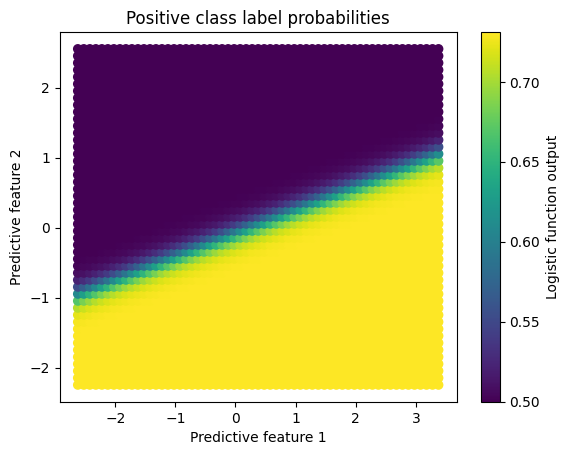

In [9]:
# relying on the imports, data preparation and model training done above...

# put our raw LiR outputs (calculated above) through the logistic function
grid_predictions = logistic(grid_predictions)

# Visualise the positive class label probability scores produced by the logistic function
plt.figure()

#plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_predictions, edgecolors='none', cmap='viridis')
# Plot the model's positive class label probability scores (2D)
plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_predictions, cmap='viridis')

# Add a colorbar to help us interpret the colours
plt.colorbar(label='Logistic function output')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Positive class label probabilities')
plt.show()

# now as a (rotatable) 3D Surface Plot with Plotly

# Reshape the predictions back to the grid shape for surface plotting
grid_predictions_reshaped = grid_predictions.reshape(grid_x.shape)

# Plot the model's positive class label probability scores (3D)
fig = go.Figure(data=[
    go.Surface(x=grid_x, y=grid_y, z=grid_predictions_reshaped, colorscale='viridis', colorbar=dict(title='Logistic function output'))
])

# add some axis labels
fig.update_layout(
    title='Positive class label probabilities',
    scene=dict(
        xaxis_title='Predictive feature 1',
        yaxis_title='Predictive feature 2',
        zaxis_title='Logistic function output',
        aspectmode='cube'
    )
)

# Show the interactive 3D plot
fig.show()

## Generalisation visualisation

Finally, let's plot the feature space generalisation. We're used to this kind of visualisation from the early weeks, and we superimpose the training data as usual, for extra context.

*    What is the shape of the decision boundary (the boundary between the regions where we predict either label)? ** Straight line / slight vertical**

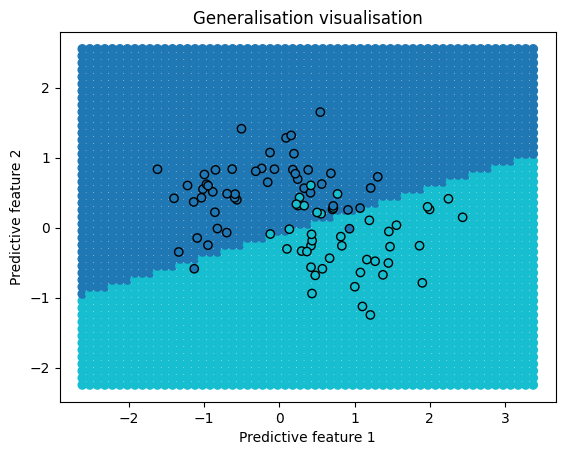

In [10]:
# relying on the imports, data preparation and model training done above...

# Prepare our own grid of testing examples to use in visualization
x_min = train_examples[:, 0].min() - 1
x_max = train_examples[:, 0].max() + 1
y_min = train_examples[:, 1].min() - 1
y_max = train_examples[:, 1].max() + 1
# adjust this to get more/less definition in the grid (takes more/less time, may need smaller plot points below)
jump = 0.1
# Get help from numpy's meshgrid() function to be fast
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, jump), np.arange(y_min, y_max, jump))
# Turn the results back into a deep table with only 2 columns
grid_examples = np.c_[grid_x.ravel(), grid_y.ravel()]

# Make predictions for each of the examples in the grid
grid_predictions = model.predict(grid_examples)

# Visualise the final generalisation
plt.figure()

# Matplotlib wants integers for the colour codes in our scatter plot: convert our string-based labels over
unique_labels, grid_labels_int = np.unique(grid_predictions, return_inverse=True)
unique_labels, train_labels_int = np.unique(train_labels, return_inverse=True)
# Plot the generalisation
plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_labels_int, cmap='tab10')
# Plot the training data
plt.scatter(train_examples[:, 0], train_examples[:, 1], c=train_labels_int, edgecolors='black', cmap='tab10')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Generalisation visualisation')
plt.show()

# Polynomial features

Recall that we can take steps to try and get around the restrictive linear relationship at the core of the logistic regressor, by adding extra features into our problem.

The 'polynomial features' (PF) approach adds extra features by multiplying existing features together, based on the power and interaction terms in a polynomial function with a fixed degree.

Let's try using this trick on the moons.csv data - see how we add extra features to the training and testing examples (see also the debug):

**Tip**: Notice we typically need to standardise after introducing the extra features (which can have very different relative ranges).

**Tip**: The decision boundary only *appears* to curve - it's still a flat hyperplane in the new higher-dimensional space which is produced by adding the polynomial features.

In [11]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/moons.csv')

# Set the name of the target feature
target_feature = 'Label'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Try adding extra polynomial features
print(f"before PF we have: {train_examples.shape[1]} features")
pf = PolynomialFeatures(degree=2, include_bias=False)
train_examples = pf.fit_transform(train_examples)
test_examples = pf.fit_transform(test_examples)
print(f"after PF we have: {train_examples.shape[1]} features")

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Create a logistic regression classification model object:
model = SGDClassifier(random_state=99, loss='log_loss')

# Fit the model to our training data
model.fit(train_examples, train_labels)

# Use the model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

before PF we have: 2 features
after PF we have: 5 features
Accuracy: 0.8166666666666667 (or 81.7 %)


## Generalisation visualisation

Let's try and visualise the feature space generalisation again. This time it's harder - we'll have to generate the extra polynomial features for all the points in our grid so that we can pass them to our model to generate predictions:

before PF we have: 2 features
after PF we have: 5 features


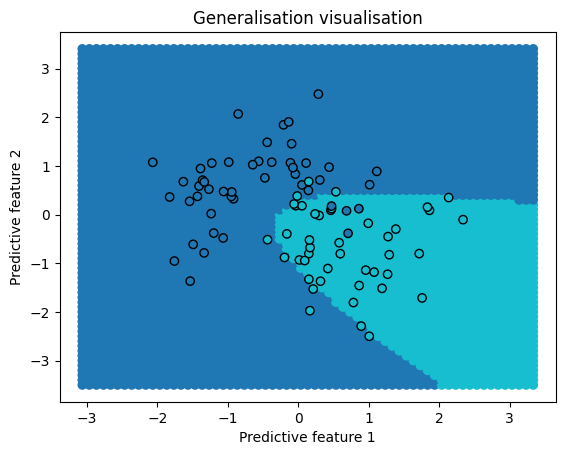

In [12]:
# relying on the imports, data preparation and model training done above...
import matplotlib.pyplot as plt

# Prepare our own grid of testing examples to use in visualization
x_min = train_examples[:, 0].min() - 1
x_max = train_examples[:, 0].max() + 1
y_min = train_examples[:, 1].min() - 1
y_max = train_examples[:, 1].max() + 1
# adjust this to get more/less definition in the grid (takes more/less time, may need smaller plot points below)
jump = 0.1
# Get help from numpy's meshgrid() function to be fast
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, jump), np.arange(y_min, y_max, jump))
# Turn the results back into a deep table with only 2 columns
grid_examples = np.c_[grid_x.ravel(), grid_y.ravel()]

# Add the polynomial features for the new grid examples
print(f"before PF we have: {grid_examples.shape[1]} features")
grid_examples = pf.fit_transform(grid_examples)
print(f"after PF we have: {grid_examples.shape[1]} features")

# Make predictions for each of the examples in the grid
grid_predictions = model.predict(grid_examples)

# Visualise the final generalisation - only using the first two predictive features (the real ones!)
plt.figure()

# Matplotlib wants integers for the colour codes in our scatter plot: convert our string-based labels over
unique_labels, grid_labels_int = np.unique(grid_predictions, return_inverse=True)
# Plot the generalisation
plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_labels_int, cmap='tab10')
# Plot the training data
plt.scatter(train_examples[:, 0], train_examples[:, 1], c=train_labels_int, edgecolors='black', cmap='tab10')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Generalisation visualisation')
plt.show()

## You try

Try using the `PolynomialFeatures` class to see if you can get a performance improvement for a logistic regressor on the biopsies.csv data:

**Tip**: you can start with a copy/paste from the example above.

**Tip**: try a degree of 2 (remember that anything higher will start to generate a _lot_ of features).

**Tip**: there's no easy way to visualise feature space generalisations for this problem (it has around 30 predictive features) - you'll need to be guided by your performance metric.

In [13]:
# Add your code on the lines below:
# IMPORTS
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# LOAD DATA
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

target_feature = 'diagnosis'

X = observations.drop(columns=target_feature)
y = observations[target_feature]

# TRAIN / TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=99, shuffle=True
)

# ----------------------------
# BASE MODEL (no polynomial features)
# ----------------------------
pipeline_base = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

scores_base = cross_val_score(
    pipeline_base,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)

print("Base model AUC:", round(scores_base.mean(), 3))

# ----------------------------
# POLYNOMIAL FEATURES (degree 2)
# ----------------------------
pipeline_poly = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2)),
    ('model', LogisticRegression(max_iter=1000))
])

scores_poly = cross_val_score(
    pipeline_poly,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)

print("Polynomial model AUC:", round(scores_poly.mean(), 3))




Base model AUC: 0.988
Polynomial model AUC: 0.987


# Extension tasks (optional)

(Extension tasks are optional. They don't map to the assessment on this module and there is no harm in skipping them. However, for people who are interested in the subject/planning to do further study, the extension tasks can help you deepen your machine learning knowledge and meet the module learning objectives more fully.)

Let's load up the biopsies.csv data to play around with:

In [ ]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

## Finding model parameters

Below is the equation for computing the local gradient (as a row vector, $\mathbf{v}^\text{r}$) at any point in the cost surface based on a matrix containing our training examples ($\mathbf{X}$), a column vector of our training labels as zeros and ones ($\mathbf{y}^\text{c}$), the current set of model parameter estimates (as a column vector, $\mathbf{a}^\text{c}$) and the logistic function ($\sigma()$):

$\mathbf{v}^\text{r}=\frac{1}{N}\mathbf{X}^{\top}(\sigma(\mathbf{X}\mathbf{a}^\text{c}) - \mathbf{y}^\text{c})$

Where $N$ is the number of training examples/labels we have.

By not worrying too much about the details of the matrix operations, see if you can use NumPy to calculate the local gradient vector based on the `SGDClassifier`'s initialisation of the model parameters (all zeros):

**Tip**: $\mathbf{X}$ and $\mathbf{y}^\text{c}$ have been set up for you as `train_examples_with_intercept` and `train_labels_column`, respectively.

**Tip**: you should get the following result, which shows the direction in which we should jump (opposite way, distance controlled by the learning rate) in order to improve the current set of model parameters.

```
[[-0.34904025]
 [-0.18794294]
 [-0.3542118 ]
 [-0.33647623]
 [-0.17155347]
 [-0.28901075]
 [-0.32879583]
 [-0.37189045]
 [-0.15723802]
 [ 0.01672058]
 [-0.26484754]
 [ 0.00386905]
 [-0.25911183]
 [-0.25067003]
 [ 0.01783396]
 [-0.14250588]
 [-0.10489748]
 [-0.19603746]
 [ 0.0015328 ]
 [-0.04089899]
 [-0.37241707]
 [-0.20910343]
 [-0.37419889]
 [-0.35005707]
 [-0.19770222]
 [-0.28313767]
 [-0.30397705]
 [-0.37482004]
 [-0.2024345 ]
 [-0.15487604]
 [ 0.13450292]]
```

In [ ]:
train_examples_with_intercept = np.c_[train_examples, np.ones((train_examples.shape[0], 1))]
# Convert to 0/1 for negative/positive class using np.where
train_labels_positive = np.where(train_labels == "Malignant", 1, 0)
train_labels_column = np.atleast_2d(train_labels_positive).T
# initialise our parameters to zeros (this is also what Scikit-learn does)
initial_params_column = np.zeros((train_examples.shape[1]+1,1))

# Add your code on the lines below:





## You try

**Would you like to re-implement a `MySGDClassifier` class for logistic regression? We have worked through the steps necessary for implementing the gradient descent during model fitting, above. (You may also have worked on a very similar `.fit()` method for `MySGDRegressor` last time - you can reuse the code.) We have also looked at how to generate predictions with NumPy matrix multiplications and a simple `logistic()` method earlier int the notebook. You would need to bring together these steps in a single class.**

Further guidance (reminders from previous extension tasks on gradient descent):

1. After calculating the local gradient the main job is to then use it to make a change in the model parameters, based on a learning rate. Hard code this learning rate nice and small to begin with, along with a relatively small maximum on the number of iterations, and print yourself out plenty of debug at each step (current model parameters, local gradient, current cost score, etc.). Can you manage to recover a reasonable set of model parameters? (Compare against Scikit-learn's results.)
2. Can you extend your approach to support stochastic gradient descent (SGD) by allowing the number of training examples that are considered in the calculation to be adjusted, and sampled at random, through a 'batch size' setting (see also our work with `np.random.choice()` in previous weeks). An epoch is then defined as the number of iterations needed until you have sampled the same number of examples as are in your original training set - move to printing debug once per epoch, and give the caller control over the maximum number of epochs. Can you give them control over some other useful options (e.g., the batch size or learning rate, or equivalents to the `tol` and `n_iter_no_change` options we used in the earlier parts of the notebook).



## Support vector machines (SVMs)

Recall that SVMs use a very similar approach to polynomial features, but that they do it in a much more efficient way by using the 'kernel trick'. This allows us, for example, to experiment with much higher degrees of polynomial (at the potential risk of overfitting). See also the optional Moodle materials for further details.

### SVM classification

Have a look over the example below, where we process the moons.csv datas using Scikit-learn's SVM classification implementation (`SVC()`) with its default kernel (radial basis function). Notice the performance increase versus LoR with second order polynomial features previously:

**Tip**: the SVM is another model that is sensitive to relative predictive feature ranges and so we are using z-score standardisation.

In [ ]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/moons.csv')

# Set the name of the target feature
target_feature = 'Label'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Create an SVM classification model object (radial basis function is the defaul kernel, but just to be clear):
model = SVC(random_state=99, kernel='rbf')

# Fit the model to our training data
model.fit(train_examples, train_labels)

# Use the model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

Accuracy: 0.8666666666666667 (or 86.7 %)


### Generalisation visualisation

Let's try and visualise the feature space generalisation again. This time it's much easier than it was with polynomial features - it is necessary to apply the kernel trick to all the points in our grid, but the `SVC` model will automatically do the job for us:

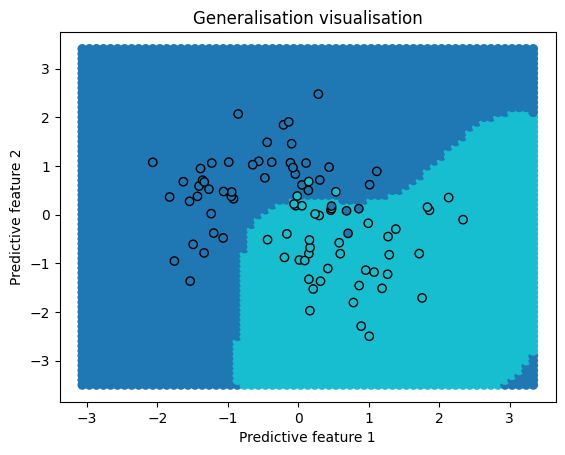

In [ ]:
# relying on the imports, data preparation and model training done above...
import matplotlib.pyplot as plt

# Prepare our own grid of testing examples to use in visualization
x_min = train_examples[:, 0].min() - 1
x_max = train_examples[:, 0].max() + 1
y_min = train_examples[:, 1].min() - 1
y_max = train_examples[:, 1].max() + 1
# adjust this to get more/less definition in the grid (takes more/less time, may need smaller plot points below)
jump = 0.1
# Get help from numpy's meshgrid() function to be fast
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, jump), np.arange(y_min, y_max, jump))
# Turn the results back into a deep table with only 2 columns
grid_examples = np.c_[grid_x.ravel(), grid_y.ravel()]

# Make predictions for each of the examples in the grid
grid_predictions = model.predict(grid_examples)

# Visualise the final generalisation - only using the first two predictive features (the real ones!)
plt.figure()

# Matplotlib wants integers for the colour codes in our scatter plot: convert our string-based labels over
unique_labels, grid_labels_int = np.unique(grid_predictions, return_inverse=True)
# Plot the generalisation
plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_labels_int, cmap='tab10')
# Plot the training data
plt.scatter(train_examples[:, 0], train_examples[:, 1], c=train_labels_int, edgecolors='black', cmap='tab10')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Generalisation visualisation')
plt.show()

### You try

See if you can reuse the SVM code from above to bring about another small improvement in performance for the biopsies.csv datas:

**Tip**: there's no easy way to visualise feature space generalisations for this problem (it has around 30 predictive features) - you'll need to be guided by your performance metric.

**Tip**: perhaps try adjusting some hyperparameters (see the optional Moodle videos for more on `C` and `gamma`).

In [ ]:
# Add your code on the lines below:





### SVM regression

SVMs can also be used for regression. See the optional Moodle materials for more details. In Scikit-learn, the relevant class is called `SVR()` and the important hyperparameters are all the same.

### You try

In the previous notebook, you conducted a full performance investigation on the diabetes_progression.csv data using a `DecisionTreeRegressor`, including improving on the basic supervised learning we've used here.

*    Using the same improved recipe you used last time, what kind of performance can we expect from an SVM regressor on the same problem? **Type your answer here**

**Tip**: start by copy/pasting your code from the previous lab - the changes you need to make should then be fairly small.

In [ ]:
from sklearn.svm import SVR

# Add your code on the lines below



